# CONUS at 1 Gt yr⁻¹ 

Plot the results from the 1Gt/yr case of [Beerling et al. (2025)](https://doi.org/10.1038/s41586-024-08429-2).

1. **Soil CO₂**.
2. **pH**.
3. **Validation**: we reproduce the published national (gross) CDR curve.
4. **CDR under E1 and E2**: optimizing for alkalinity export vs. for pH. CDR here includes carbonate
   precipitation.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
from pathlib import Path
import numpy as np, xarray as xr, matplotlib as mpl, matplotlib.pyplot as plt
from beerling_analysis import io

mpl.rcParams.update({"font.size": 10, "figure.dpi": 120, "axes.grid": False})
OI = dict(blue="#0072B2", vermillion="#D55E00", green="#009E73",
          orange="#E69F00", purple="#CC79A7", sky="#56B4E9", grey="0.45")

TAG      = "e0-conus-1gt"
ROOT     = "s3://carbonplan-carbon-removal/ew-workflows-data/beerling-2025-model-extension"
POSTPROC = os.environ.get("BEERLING_POSTPROC", f"{ROOT}/postproc/{TAG}")
FIGDIR   = Path("../figures") if Path("../figures").is_dir() else Path("figures")
FIGDIR.mkdir(exist_ok=True)

pt   = xr.open_zarr(f"{POSTPROC}/point.zarr").load()
SCEN = int(str(pt.attrs["scenario"]).lstrip("S"))
YRS  = pt.time.values

# A point-year counts once rock has been applied there. Before start_year the
# column is the control soil and belongs in no distribution of the deployment.
ACT  = pt.time >= pt.start_year
AREA = (pt.area_ha * xr.ones_like(pt.time, dtype=float)).where(ACT)

def flat(v, positive=False):
    """Active point-years of `v`, paired with their hectares. NaNs dropped."""
    x, w = pt[v].where(ACT).values.ravel(), AREA.values.ravel()
    m = np.isfinite(x) & np.isfinite(w)
    if positive:
        m &= x > 0
    return x[m], w[m]

def wq(x, w, q):
    """Weighted quantile, linear interpolation on the midpoint CDF."""
    o = np.argsort(x); x, w = x[o], w[o]
    return np.interp(q, (np.cumsum(w) - 0.5 * w) / w.sum(), x)

def wfrac(x, w, thr):
    return float(w[x > thr].sum() / w.sum())

def national(v):
    """Per-point cumulative t CO2 -> national ANNUAL rate in Gt CO2/yr.

    `cdr_total` and its _e1/_e2 siblings are cumulative per point; the paper's
    Fig. 1a is a rate. Difference first, then sum -- points start in different
    years, so the national cumulative is not a curve any one point traces."""
    cum = pt[v].fillna(0.0)
    return ((cum - cum.shift(time=1, fill_value=0.0)).sum("point") / 1e9).values

print(f"{POSTPROC}/point.zarr")
print(f"  S{SCEN}  {pt.sizes['point']:,} points / {int(pt.cluster.to_series().nunique())} "
      f"clusters  {float(pt.area_ha.sum())/1e6:.2f} M ha  {int(YRS[0])}-{int(YRS[-1])}")
print(f"  {int(ACT.sum()):,} deployed point-years of {pt.sizes['point'] * pt.sizes['time']:,}")

s3://carbonplan-carbon-removal/ew-workflows-data/beerling-2025-model-extension/postproc/e0-conus-1gt/point.zarr
  S1  2,322 points / 221 clusters  24.49 M ha  2020-2070
  60,330 deployed point-years of 118,422


In [2]:
xr.open_zarr(f"{POSTPROC}/point.zarr").load()

<xarray.Dataset> Size: 40MB
Dimensions:          (point: 2322, time: 51, soil_level: 7)
Coordinates: (12/16)
  * point            (point) int64 19kB 31 32 33 34 35 ... 5480 5481 5482 5483
    area_ha          (point) float64 19kB 3.533e+03 3.416e+03 ... 2.197e+04
    cluster          (point) int64 19kB 3 3 3 3 3 4 ... 437 437 437 437 437 437
    crop             (point) StringDType() 37kB 'Temperate Maize' ... 'Temper...
    eta              (point) float64 19kB 0.8524 0.8524 0.8524 ... 0.8537 0.8537
    lind             (point) int64 19kB 186062 186830 187598 ... 212173 208338
    ...               ...
    source_state     (point) StringDType() 37kB 'Idaho' ... 'North_Carolina'
    start_year       (point) int16 5kB 2049 2049 2049 2049 ... 2055 2055 2055
    w                (point) float64 19kB 0.4066 0.4066 0.4066 ... 0.9271 0.9271
  * time             (time) int64 408B 2020 2021 2022 2023 ... 2068 2069 2070
  * soil_level       (soil_level) int64 56B 1 2 3 4 5 6 7
    pH0              (point, soil_level) float64 130kB 7.2 7.26 ... 6.897 7.294
Data variables: (12/41)
    alk              (point, time) float64 947kB nan nan nan ... 0.03158 0.03207
    alk_added        (point, time) float64 947kB nan nan nan ... 0.01784 0.01789
    alk_cap          (point, time) float64 947kB nan nan ... 0.002644 0.003221
    alk_export_e2    (point, time) float64 947kB nan nan nan ... 81.15 87.58
    c2b              (point, time) float64 947kB nan nan nan ... 0.2411 0.2418
    Ca_export        (point, time) float64 947kB nan nan nan ... 19.11 20.8 22.2
    ...               ...
    pH_diag          (point, time) float64 947kB nan nan nan ... 7.38 7.384
    pH_e1            (point, time) float64 947kB nan nan nan ... 8.912 8.906
    pH_thermo        (point, time) float64 947kB nan nan nan ... 9.001 8.998
    q                (point, time) float64 947kB nan nan nan ... 0.8366 0.721
    rock             (point, time) float64 947kB nan nan nan ... 600.0 640.0
    soil_co2         (point, time) float64 947kB nan nan ... 1.907e+03 2.046e+03
Attributes:
    tag:         e0-conus-1gt
    scenario:    S1
    experiment:  E0
    source:      s3://carbonplan-carbon-removal/ew-workflows-data/beerling-20...
    e1:          True
    e2:          True
    note:        mineralogies mixed at w; depth collapsed by unweighted mean ...

## 1. Modeled vs. equilibrium-required soil CO2

**a** Both distributions. **b** Required ÷ modeled per point-year (can't be computed from the annual
postprocessed data, because of Jensen's inequality and carbonate nonlinearity).

modelled soil pCO2   median     1,870 ppm   (p5 1,089, p95 2,206)
required  soil pCO2  median   161,475 ppm   (p5 33,642, p95 277,333)  = 16% of an atmosphere of pure CO2
multiple             median        71 x     (p5 23, p95 115)
0.75% of deployed cropland-years need a NEGATIVE pCO2 -- unclosable at any value


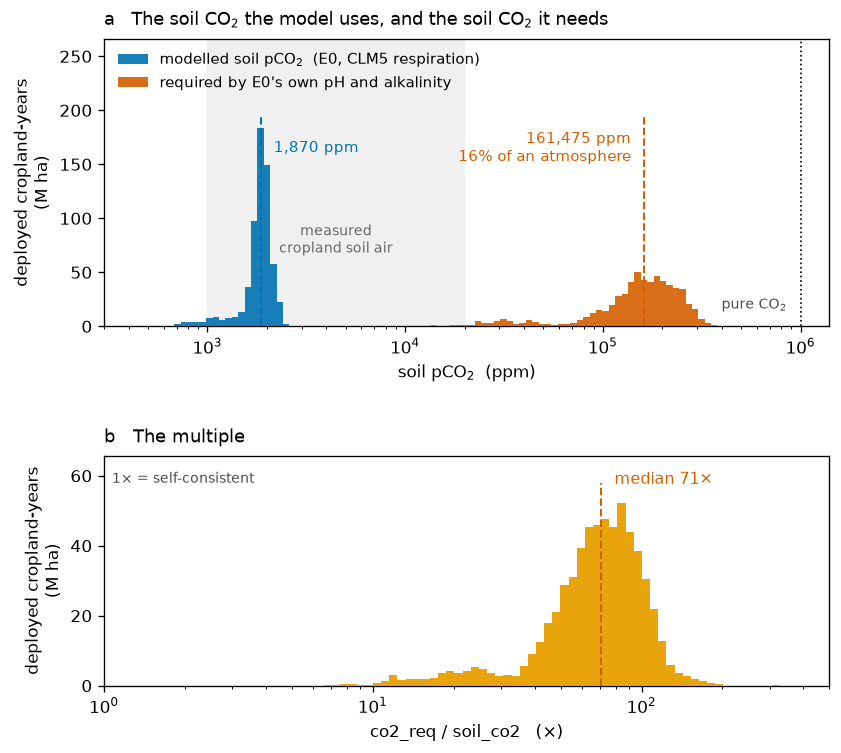

In [3]:
co2, wco2 = flat("soil_co2", positive=True)
req, wreq = flat("co2_req",  positive=True)
rat, wrat = flat("co2_req_ratio", positive=True)
allreq, wallreq = flat("co2_req")

m_co2, m_req, m_rat = wq(co2, wco2, .5), wq(req, wreq, .5), wq(rat, wrat, .5)
neg = float(wallreq[allreq <= 0].sum() / wallreq.sum())

print(f"modelled soil pCO2   median {m_co2:9,.0f} ppm   "
      f"(p5 {wq(co2, wco2, .05):,.0f}, p95 {wq(co2, wco2, .95):,.0f})")
print(f"required  soil pCO2  median {m_req:9,.0f} ppm   "
      f"(p5 {wq(req, wreq, .05):,.0f}, p95 {wq(req, wreq, .95):,.0f})"
      f"  = {m_req/1e6:.0%} of an atmosphere of pure CO2")
print(f"multiple             median {m_rat:9,.0f} x     "
      f"(p5 {wq(rat, wrat, .05):.0f}, p95 {wq(rat, wrat, .95):.0f})")
print(f"{neg:.2%} of deployed cropland-years need a NEGATIVE pCO2 -- unclosable at any value")

fig, axes = plt.subplots(2, 1, figsize=(7.8, 7.0),
                         gridspec_kw=dict(hspace=.50, height_ratios=[1.25, 1]))

# -- a: two soil co2 distributions --------------------------------
ax = axes[0]
bins = np.logspace(np.log10(3e2), 6, 110)
ax.axvspan(1e3, 2e4, color=OI["grey"], alpha=.10, lw=0, zorder=0)
ax.hist(co2, bins=bins, weights=wco2 / 1e6, color=OI["blue"], alpha=.9, zorder=3,
        label="modelled soil pCO$_2$  (E0, CLM5 respiration)")
ax.hist(req, bins=bins, weights=wreq / 1e6, color=OI["vermillion"], alpha=.9, zorder=3,
        label="required by E0's own pH and alkalinity")
ax.set_xscale("log"); ax.set_xlim(3e2, 1.4e6)
top = ax.get_ylim()[1] * 1.38; ax.set_ylim(0, top)
ax.vlines(m_co2, 0, top * .74, color=OI["blue"],       ls="--", lw=1.2, zorder=4)
ax.vlines(m_req, 0, top * .74, color=OI["vermillion"], ls="--", lw=1.2, zorder=4)
ax.axvline(1e6, color="k", lw=1.0, ls=":", zorder=2)
ax.text(m_co2 * 1.16, top * .62, f"{m_co2:,.0f} ppm", color=OI["blue"],
        fontsize=9, ha="left", va="center")
ax.text(m_req * .86, top * .62, f"{m_req:,.0f} ppm\n{m_req/1e6:.0%} of an atmosphere",
        color=OI["vermillion"], fontsize=9, ha="right", va="center")
ax.text(np.sqrt(1e3 * 2e4), top * .30, "measured\ncropland soil air",
        fontsize=8.5, color="0.4", ha="center", va="center")
ax.text(8.5e5, top * .06, "pure CO$_2$", fontsize=8.5, color="0.3", ha="right")
ax.set_xlabel("soil pCO$_2$  (ppm)")
ax.set_ylabel("deployed cropland-years\n(M ha)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("a   The soil CO$_2$ the model uses, and the soil CO$_2$ it needs",
             loc="left", fontsize=10.5, pad=8)

# -- b: soil CO2 multiplier -------------------------------------------------------
ax = axes[1]
ax.hist(rat, bins=np.logspace(0, np.log10(500), 90), weights=wrat / 1e6,
        color=OI["orange"], alpha=.95, zorder=3)
ax.set_xscale("log"); ax.set_xlim(1, 500)
top = ax.get_ylim()[1] * 1.20; ax.set_ylim(0, top)
ax.axvline(1, color="k", lw=1.0, ls=":")
ax.vlines(m_rat, 0, top * .88, color=OI["vermillion"], ls="--", lw=1.2, zorder=4)
ax.text(m_rat * 1.12, top * .93, f"median {m_rat:.0f}×", color=OI["vermillion"],
        fontsize=9.5, va="top", ha="left")
ax.text(1.07, top * .93, "1× = self-consistent", fontsize=8.5, color="0.3",
        ha="left", va="top")
ax.set_xlabel("co2_req / soil_co2   (×)")
ax.set_ylabel("deployed cropland-years\n(M ha)")
ax.set_title("b   The multiple", loc="left", fontsize=10.5, pad=8)

fig.savefig(FIGDIR / "05_fig1_soil_co2.png", bbox_inches="tight", dpi=200)
plt.show()

## 2. Porewater pH with a closed carbonate system

The pH needed to carry the modeled alkalinity at the modeled soil CO2 (E1).

column-mean porewater pH, area-weighted median over deployed cropland-years
  control (no feedstock)  5.97
  E0  modelled            7.11   (pH_col, the published reduction: 7.11)
  E1  carbonate-consistent  8.79   (+1.69 vs E0, +2.82 vs control)
above pH 7.5:  E0 11.3%   E1 99.0%


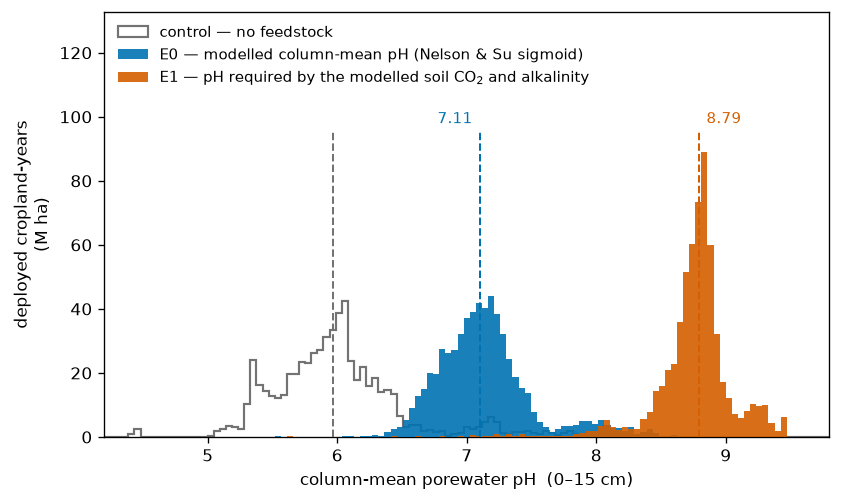

In [4]:
ph0, w0 = flat("pH_diag")      # E0's own pH, on pH_e1's 100/yr grid
ph1, w1 = flat("pH_e1")        # what the carbonate system puts that state at
phc, wc = flat("pH_ctrl")      # same soil, feedstock removed
phm, wm = flat("pH_col")       # the monthly reduction, validated vs published

m0, m1, mc, mm = (wq(ph0, w0, .5), wq(ph1, w1, .5), wq(phc, wc, .5), wq(phm, wm, .5))
f0, f1 = wfrac(ph0, w0, 7.5), wfrac(ph1, w1, 7.5)

print(f"column-mean porewater pH, area-weighted median over deployed cropland-years")
print(f"  control (no feedstock)  {mc:.2f}")
print(f"  E0  modelled            {m0:.2f}   (pH_col, the published reduction: {mm:.2f})")
print(f"  E1  carbonate-consistent{m1:6.2f}   ({m1 - m0:+.2f} vs E0, {m1 - mc:+.2f} vs control)")
print(f"above pH 7.5:  E0 {f0:.1%}   E1 {f1:.1%}")

fig, ax = plt.subplots(figsize=(7.8, 4.6))
bins = np.linspace(4.2, 9.8, 120)
ax.hist(phc, bins=bins, weights=wc / 1e6, histtype="step", lw=1.3, color=OI["grey"],
        zorder=2, label="control — no feedstock")
ax.hist(ph0, bins=bins, weights=w0 / 1e6, color=OI["blue"], alpha=.9, zorder=3,
        label="E0 — modelled column-mean pH (Nelson & Su sigmoid)")
ax.hist(ph1, bins=bins, weights=w1 / 1e6, color=OI["vermillion"], alpha=.9, zorder=3,
        label="E1 — pH required by the modelled soil CO$_2$ and alkalinity")

top = ax.get_ylim()[1] * 1.42; ax.set_ylim(0, top); ax.set_xlim(4.2, 9.8)
##  Every rule stops below the legend band; the value sits at the top of its rule.
# ax.vlines(7.5, 0, top * .80, color="k", lw=1.0, ls=":", zorder=4)
for m, c in [(mc, OI["grey"]), (m0, OI["blue"]), (m1, OI["vermillion"])]:
    ax.vlines(m, 0, top * .72, color=c, ls="--", lw=1.2, zorder=5)
# ax.annotate("", xy=(m1, top * .58), xytext=(m0, top * .58),
#             arrowprops=dict(arrowstyle="->", color="0.25", lw=1.2))
# ax.text((m0 + m1) / 2, top * .60, f"+{m1 - m0:.2f} units", ha="center",
#         fontsize=9.5, color="0.2")
ax.text(m0 - .06, top * .73, f"{m0:.2f}", color=OI["blue"], fontsize=9,
        ha="right", va="bottom")
ax.text(m1 + .06, top * .73, f"{m1:.2f}", color=OI["vermillion"], fontsize=9,
        ha="left", va="bottom")
# ax.text(7.56, top * .30, f"pH 7.5\nE0 {f0:.0%} above\nE1 {f1:.0%} above",
#         fontsize=8.5, color="0.3", va="center")
ax.set_xlabel("column-mean porewater pH  (0–15 cm)")
ax.set_ylabel("deployed cropland-years\n(M ha)")
ax.legend(frameon=False, fontsize=9, loc="upper left")

fig.savefig(FIGDIR / "05_fig2_pH.png", bbox_inches="tight", dpi=200)
plt.show()

## 3. Validation: national CDR

The paper's Fig. 1a is net CDR; we simulate gross, so we compare gross and show net for reference.

annual national CDR, Gt CO2/yr        2050      2070
  ours (E0, point.zarr)             0.1618    0.2365
  published deposit, gross (N2)     0.1618    0.2365
  published, N1-N3 envelope        0.124-0.199    0.186-0.287
  published, net of LCA terms       0.1531    0.2514   (paper: 0.16 +/- 0.04, 0.25 +/- 0.05)

reproduction: max |ours - published| = 5,365 t CO2/yr, max relative error 2.9e-04


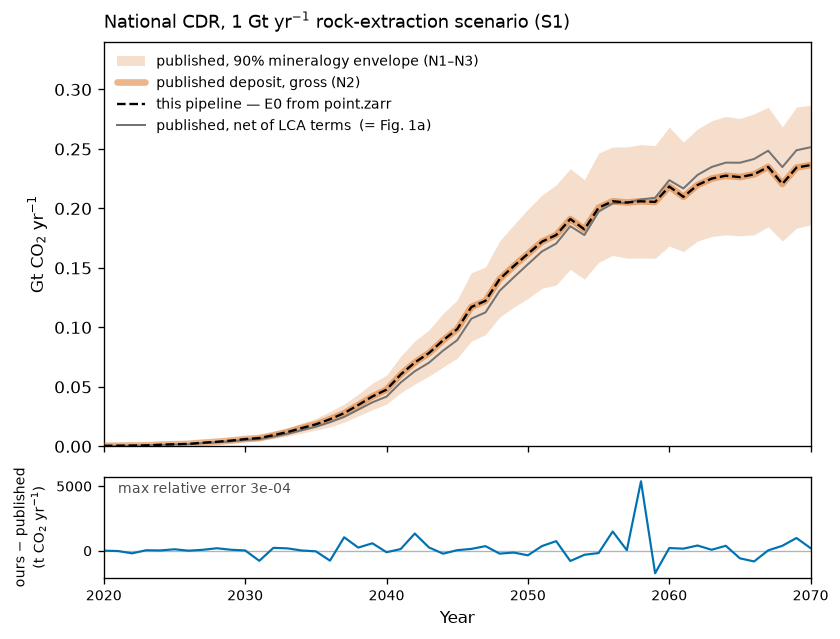

In [ ]:
FL   = ["CO2", "grem", "trem", "spem", "feem_P", "feem_K"]
dbs  = {f: io.load_published(f) for f in FL}
ids  = [int(p) for p in pt.point.values]     # point IS the key of the published pickles

pub   = {N: {f: sum(dbs[f][p][f"{f}_a_b"][f"S{SCEN}_U1_N{N}_p100"].values for p in ids) / 1e9
             for f in FL} for N in (1, 2, 3)}
gross = {N: pub[N]["CO2"] for N in pub}
net   = {N: pub[N]["CO2"] - sum(pub[N][f] for f in FL[1:]) for N in pub}

ours = national("cdr_total")
d    = (ours - gross[2]) * 1e9                                  # t CO2/yr
rel  = np.abs(d) / np.where(gross[2] > 0, gross[2] * 1e9, np.nan)

print(f"annual national CDR, Gt CO2/yr        2050      2070")
print(f"  ours (E0, point.zarr)           {ours[YRS == 2050][0]:8.4f}  {ours[-1]:8.4f}")
print(f"  published deposit, gross (N2)   {gross[2][YRS == 2050][0]:8.4f}  {gross[2][-1]:8.4f}")
print(f"  published, N1-N3 envelope        {gross[1][YRS == 2050][0]:.3f}-{gross[3][YRS == 2050][0]:.3f}"
      f"    {gross[1][-1]:.3f}-{gross[3][-1]:.3f}")
print(f"  published, net of LCA terms     {net[2][YRS == 2050][0]:8.4f}  {net[2][-1]:8.4f}"
      f"   (paper: 0.16 +/- 0.04, 0.25 +/- 0.05)")
print(f"\nreproduction: max |ours - published| = {np.abs(d).max():,.0f} t CO2/yr, "
      f"max relative error {np.nanmax(rel):.1e}")
assert np.nanmax(rel) < 1e-3, "national curve does not reproduce the published deposit"

fig, axes = plt.subplots(2, 1, figsize=(7.6, 5.8), sharex=True,
                         gridspec_kw=dict(height_ratios=[4, 1], hspace=.12))

ax = axes[0]
ax.fill_between(YRS, gross[1], gross[3], color=OI["vermillion"], alpha=.20, lw=0,
                zorder=2, label="published, 90% mineralogy envelope (N1–N3)")
ax.plot(YRS, gross[2], color=OI["vermillion"], lw=4.0, alpha=.45, zorder=3,
        solid_capstyle="round", label="published deposit, gross (N2)")
ax.plot(YRS, ours, color="k", lw=1.4, ls="--", zorder=5,
        label="this pipeline — E0 from point.zarr")
ax.plot(YRS, net[2], color=OI["grey"], lw=1.2, zorder=4,
        label="published, net of LCA terms  (= Fig. 1a)")
ax.set_xlim(2020, 2070); ax.set_ylim(0, .34)
ax.set_ylabel("Gt CO$_2$ yr$^{-1}$")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title(f"National CDR, {SCEN} Gt yr$^{{-1}}$ rock-extraction scenario (S{SCEN})",
             loc="left", fontsize=10.5, pad=8)

ax = axes[1]
ax.axhline(0, color="0.7", lw=.8)
ax.plot(YRS, d, color=OI["blue"], lw=1.3)
ax.set_xlabel("Year")
ax.set_ylabel("ours − published\n(t CO$_2$ yr$^{-1}$)", fontsize=8.5)
ax.tick_params(labelsize=8.5)
ax.text(2021, ax.get_ylim()[1] * .78,
        f"max relative error {np.nanmax(rel):.0e}", fontsize=8.5, color="0.3")

# fig.savefig(FIGDIR / "05_fig3_national_cdr.png", bbox_inches="tight", dpi=200)
plt.show()

## 4. National CDR under E1 and E2

- **E1**: keep alkalinity release; pH and SIC formation rise.
- **E2**: keep pCO2 and pH

         2070 rate    cumulative 2020-2070
E0       0.236 Gt/yr            5.58 Gt
E1       0.207 Gt/yr            4.88 Gt   (87% of E0)
E2       0.083 Gt/yr            1.86 Gt   (33% of E0)


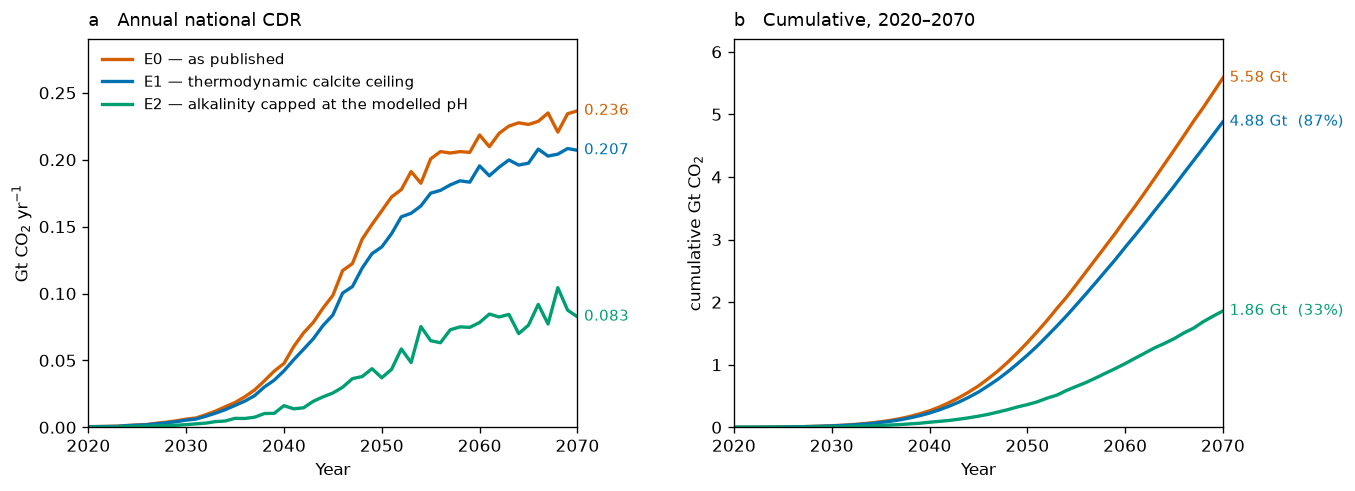

In [6]:
SER = [("E0", "cdr_total",    OI["vermillion"], "E0 — as published"),
       ("E1", "cdr_total_e1", OI["blue"],       "E1 — thermodynamic calcite ceiling"),
       ("E2", "cdr_total_e2", OI["green"],      "E2 — alkalinity capped at the modelled pH")]

rate = {k: national(v) for k, v, _, _ in SER}
cum  = {k: (pt[v].fillna(0.0).sum("point") / 1e9).values for k, v, _, _ in SER}

e0 = cum["E0"][-1]
print(f"{'':4s}  {'2070 rate':>12s}  {'cumulative 2020-2070':>22s}")
for k, _, _, _ in SER:
    share = "" if k == "E0" else f"   ({cum[k][-1] / e0:.0%} of E0)"
    print(f"{k:4s}  {rate[k][-1]:8.3f} Gt/yr  {cum[k][-1]:14.2f} Gt{share}")

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2))
fig.subplots_adjust(wspace=.32)

ax = axes[0]
for k, _, c, lab in SER:
    ax.plot(YRS, rate[k], color=c, lw=2.0, label=lab)
    ax.annotate(f"{rate[k][-1]:.3f}", xy=(2070, rate[k][-1]), xytext=(4, 0),
                textcoords="offset points", color=c, fontsize=9, va="center")
ax.set_xlim(2020, 2070); ax.set_ylim(0, .29)
ax.set_xlabel("Year"); ax.set_ylabel("Gt CO$_2$ yr$^{-1}$")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("a   Annual national CDR", loc="left", fontsize=10.5, pad=8)

ax = axes[1]
for k, _, c, _ in SER:
    ax.plot(YRS, cum[k], color=c, lw=2.0)
    ax.annotate(f"{cum[k][-1]:.2f} Gt" +
                ("" if k == "E0" else f"  ({cum[k][-1] / cum['E0'][-1]:.0%})"),
                xy=(2070, cum[k][-1]), xytext=(4, 0), textcoords="offset points",
                color=c, fontsize=9, va="center")
ax.set_xlim(2020, 2070); ax.set_ylim(0, 6.2)
ax.set_xlabel("Year"); ax.set_ylabel("cumulative Gt CO$_2$")
ax.set_title("b   Cumulative, 2020–2070", loc="left", fontsize=10.5, pad=8)

fig.savefig(FIGDIR / "05_fig4_e0_e1_e2.png", bbox_inches="tight", dpi=200)
plt.show()

metric: cdr_export  (t CO2/ha, area-weighted)
         2070 rate    cumulative 2020-2070
E0       0.190 Gt/yr            4.44 Gt
E1       0.120 Gt/yr            2.75 Gt   (62% of E0)
E2       0.036 Gt/yr            0.72 Gt   (16% of E0)


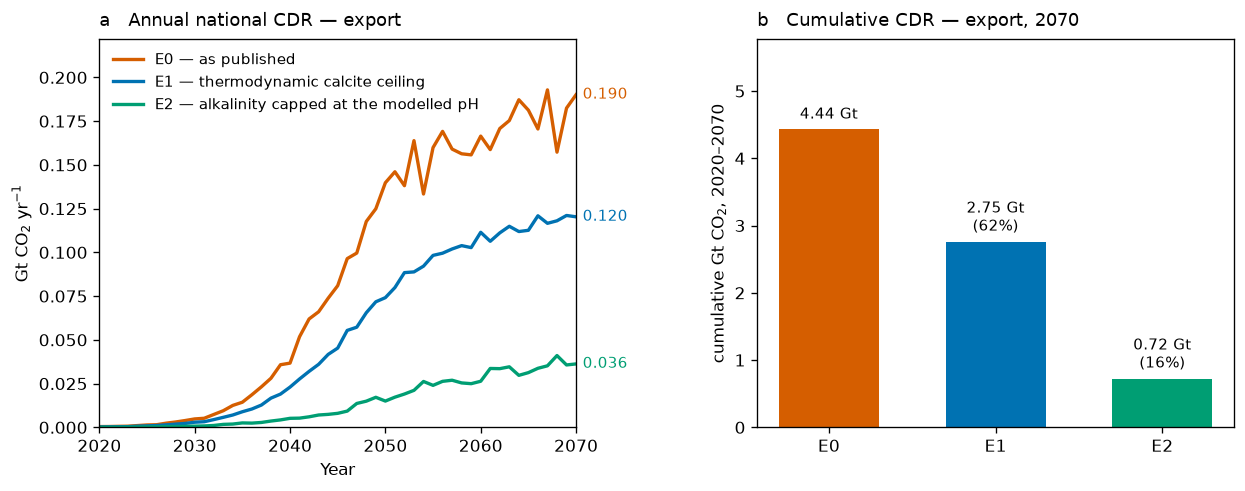

In [7]:
METRIC = "export"   # "total" -- CDR credited at the point (dissolution + SIC)
                    # "export" -- CDR that actually leaves the field as exported alkalinity

# `cdr_total` (+ _e1/_e2) is already national (t CO2, area baked in). `cdr_export`
# (+ _e1/_e2) is per-hectare (t CO2/ha) and needs multiplying by area_ha first.
METRIC_VAR = dict(total=dict(base="cdr_total",  per_ha=False),
                   export=dict(base="cdr_export", per_ha=True))[METRIC]
BASE, PER_HA = METRIC_VAR["base"], METRIC_VAR["per_ha"]

def national_m(suffix):
    """Same as `national()`, but scales per-hectare metrics by area_ha first."""
    x = pt[BASE + suffix]
    if PER_HA:
        x = x * pt.area_ha
    cum = x.fillna(0.0)
    return ((cum - cum.shift(time=1, fill_value=0.0)).sum("point") / 1e9).values

def cumulative_m(suffix):
    x = pt[BASE + suffix]
    if PER_HA:
        x = x * pt.area_ha
    return (x.fillna(0.0).sum("point") / 1e9).values

SERM = [("E0", "",    OI["vermillion"], "E0 — as published"),
        ("E1", "_e1", OI["blue"],       "E1 — thermodynamic calcite ceiling"),
        ("E2", "_e2", OI["green"],      "E2 — alkalinity capped at the modelled pH")]

ratem = {k: national_m(suf)   for k, suf, _, _ in SERM}
cumm  = {k: cumulative_m(suf) for k, suf, _, _ in SERM}

e0m = cumm["E0"][-1]
print(f"metric: {BASE}  ({'t CO2/ha, area-weighted' if PER_HA else 't CO2, national'})")
print(f"{'':4s}  {'2070 rate':>12s}  {'cumulative 2020-2070':>22s}")
for k, _, _, _ in SERM:
    share = "" if k == "E0" else f"   ({cumm[k][-1] / e0m:.0%} of E0)"
    print(f"{k:4s}  {ratem[k][-1]:8.3f} Gt/yr  {cumm[k][-1]:14.2f} Gt{share}")

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2))
fig.subplots_adjust(wspace=.38)

# -- a: annual national rate, same style as panel a above -------------------
ax = axes[0]
for k, _, c, lab in SERM:
    ax.plot(YRS, ratem[k], color=c, lw=2.0, label=lab)
    ax.annotate(f"{ratem[k][-1]:.3f}", xy=(2070, ratem[k][-1]), xytext=(4, 0),
                textcoords="offset points", color=c, fontsize=9, va="center")
ax.set_xlim(2020, 2070)
ax.set_ylim(0, max(r.max() for r in ratem.values()) * 1.15)
ax.set_xlabel("Year"); ax.set_ylabel("Gt CO$_2$ yr$^{-1}$")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title(f"a   Annual national CDR — {METRIC}", loc="left", fontsize=10.5, pad=8)

# -- b: cumulative CDR at the final year, one bar per case -------------------
ax = axes[1]
xs = np.arange(len(SERM))
vals = [cumm[k][-1] for k, _, _, _ in SERM]
ax.bar(xs, vals, color=[c for _, _, c, _ in SERM], width=.6)
for x, (k, _, _, _), val in zip(xs, SERM, vals):
    share = "" if k == "E0" else f"\n({val / e0m:.0%})"
    ax.annotate(f"{val:.2f} Gt{share}", xy=(x, val), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels([k for k, _, _, _ in SERM])
ax.set_ylim(0, max(vals) * 1.30)
ax.set_ylabel(f"cumulative Gt CO$_2$, {YRS[0]}–{YRS[-1]}")
ax.set_title(f"b   Cumulative CDR — {METRIC}, {YRS[-1]}", loc="left", fontsize=10.5, pad=8)

fig.savefig(FIGDIR / f"05_fig4b_{METRIC}_e0_e1_e2.png", bbox_inches="tight", dpi=200)
plt.show()